<a href="https://colab.research.google.com/github/neuralstack-hub/DAV-LAB/blob/main/DAV7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset:
   Hours  Attendance  Marks
0      1          60     35
1      2          72     40
2      3          68     50
3      4          80     55
4      5          75     65
5      6          90     70
6      7          85     75
7      8          95     85

--- SIMPLE LINEAR REGRESSION ---
Intercept: 27.499999999999996
Coefficient: 7.083333333333334
Predicted Marks: [34.58333333 41.66666667 48.75       55.83333333 62.91666667 70.
 77.08333333 84.16666667]
R-squared: 0.993127147766323
RMSE: 1.3501543121683015


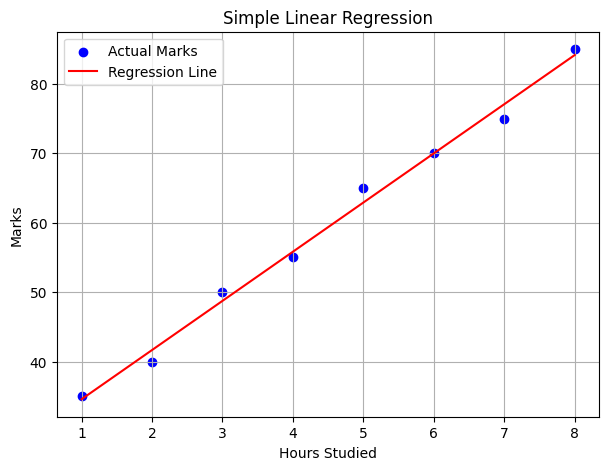


--- MULTIPLE LINEAR REGRESSION ---
Intercept: 35.376459741856166
Coefficients: [ 7.68054702 -0.13521819]
Predicted Marks: [34.94391518 41.00184388 49.22326368 55.28119238 63.63783036 69.29010449
 77.64674247 83.97510756]
R-squared: 0.9942954541957196
RMSE: 1.2300575763179389


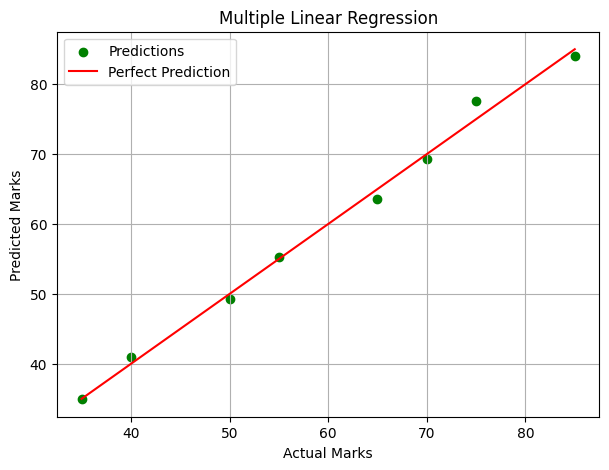

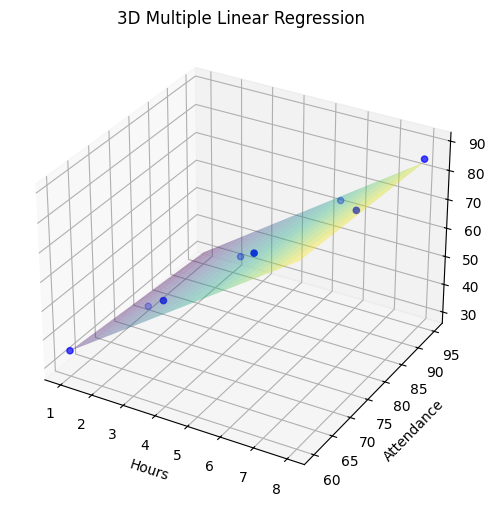

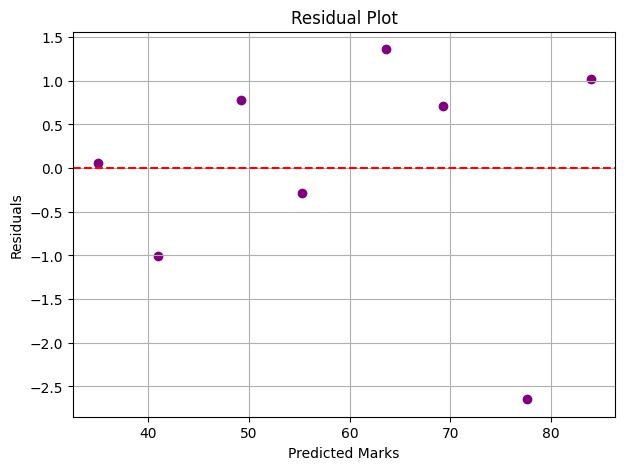

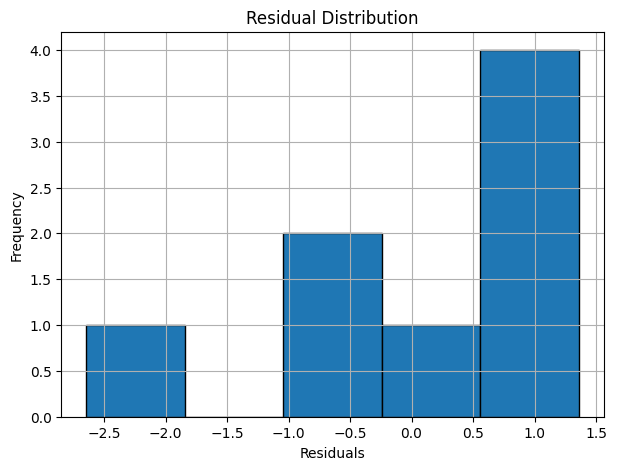


----- MODEL COMPARISON -----
Simple Linear Regression
R2 Score: 0.993127147766323
RMSE: 1.3501543121683015

Multiple Linear Regression
R2 Score: 0.9942954541957196
RMSE: 1.2300575763179389

Regression Models Completed Successfully!


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from mpl_toolkits.mplot3d import Axes3D

# 1. Create Dataset
data = pd.DataFrame({
    'Hours': [1, 2, 3, 4, 5, 6, 7, 8],
    'Attendance': [60, 72, 68, 80, 75, 90, 85, 95],
    'Marks': [35, 40, 50, 55, 65, 70, 75, 85]
})

print("Dataset:")
print(data)

y = data['Marks']


# 2. Simple Linear Regression
X = data[['Hours']]

model = LinearRegression()
model.fit(X, y)

pred = model.predict(X)

print("\n--- SIMPLE LINEAR REGRESSION ---")
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])
print("Predicted Marks:", pred)

r2 = r2_score(y, pred)
rmse = np.sqrt(mean_squared_error(y, pred))

print("R-squared:", r2)
print("RMSE:", rmse)


# 3. Simple Linear Regression Graph
plt.figure(figsize=(7, 5))
plt.scatter(data['Hours'], y, color='blue', label='Actual Marks')
plt.plot(data['Hours'], pred, color='red', label='Regression Line')
plt.xlabel("Hours Studied")
plt.ylabel("Marks")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid()
plt.show()


# 4. Multiple Linear Regression
X_multi = data[['Hours', 'Attendance']]

multi_model = LinearRegression()
multi_model.fit(X_multi, y)

multi_pred = multi_model.predict(X_multi)

print("\n--- MULTIPLE LINEAR REGRESSION ---")
print("Intercept:", multi_model.intercept_)
print("Coefficients:", multi_model.coef_)
print("Predicted Marks:", multi_pred)


# 5. Evaluate Multiple Regression
r2_multi = r2_score(y, multi_pred)
rmse_multi = np.sqrt(mean_squared_error(y, multi_pred))

print("R-squared:", r2_multi)
print("RMSE:", rmse_multi)


# 6. Actual vs Predicted Graph
plt.figure(figsize=(7, 5))
plt.scatter(y, multi_pred, color='green', label='Predictions')
plt.plot([y.min(), y.max()], [y.min(), y.max()],
         color='red', label='Perfect Prediction')
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Multiple Linear Regression")
plt.legend()
plt.grid()
plt.show()


# 7. 3D Regression Graph
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(data['Hours'], data['Attendance'], y,
           color='blue', label='Actual Data')

h = np.linspace(data['Hours'].min(), data['Hours'].max(), 20)
a = np.linspace(data['Attendance'].min(), data['Attendance'].max(), 20)

H, A = np.meshgrid(h, a)

Z = multi_model.predict(
    pd.DataFrame({
        'Hours': H.ravel(),
        'Attendance': A.ravel()
    })
).reshape(H.shape)

ax.plot_surface(H, A, Z, alpha=0.4, cmap='viridis')

ax.set_xlabel("Hours")
ax.set_ylabel("Attendance")
ax.set_zlabel("Marks")
ax.set_title("3D Multiple Linear Regression")
plt.show()


# 8. Residual Plot
residuals = y - multi_pred

plt.figure(figsize=(7, 5))
plt.scatter(multi_pred, residuals, color='purple')
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Marks")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid()
plt.show()


# 9. Residual Distribution
plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=5, edgecolor='black')
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution")
plt.grid()
plt.show()


# 10. Final Model Comparison
print("\n----- MODEL COMPARISON -----")

print("Simple Linear Regression")
print("R2 Score:", r2)
print("RMSE:", rmse)

print("\nMultiple Linear Regression")
print("R2 Score:", r2_multi)
print("RMSE:", rmse_multi)

print("\nRegression Models Completed Successfully!")
